**Reading note.** This notebook records the Week 6 analysis. Later held-out tests did not find a consistent forecasting advantage for the MPS gauges. See [the final findings](../week7/FINDINGS.md) before interpreting these charts as risk signals.


# Case study — the 2023 regional-bank collapse: does the higher-order gauge separate a doomed book from its control?

**The design.** Two purpose-built portfolios over 2018-01 → 2023-03-31:

* **Combined book (9 banks):** First Republic (**FRC** — the second-largest bank failure in US
  history, seized 2023-05-01) plus eight surviving regional peers: USB, PNC, FITB, KEY, RF,
  HBAN, MTB, ZION.
* **Control book (8 banks):** the same eight survivors, without FRC.

Identical pipeline on both. Any difference between the two books' fragility readings is the
**marginal contribution of the failing bank** — the cleanest attribution design available.

**Disclosures.** SVB and Signature's pre-2022 price histories are not recoverable from free
sources (delisted; CRSP access not available on this machine), so First Republic — whose collapse
was slower-moving and therefore a *richer* dependence event — represents the failure cohort. FRC's
history comes through its post-delisting ticker (FRCB), verified continuous. Comerica (CMA) was
dropped for the same reason (delisted in the 2026 Fifth Third merger). Both choices are
conservative: fewer stressed names in the combined book makes separation *harder*, not easier.

**The gauge.** Same $\Delta_{HO}$ pipeline as the main Complexity gauge — four walk-forward
Markov-switching legs per book (Born $\chi{=}8$, Born $\chi{=}1$, Gaussian full, Gaussian diag;
$K{=}2$, $d{=}8$, sticky 120, refit every 252 days, 350-day minimum train):

$$\Delta_{HO}(t) \;=\; \big[\ell^{B}_{\chi=8}(t) - \ell^{B}_{\chi=1}(t)\big]
\;-\; \big[\ell^{G}_{\mathrm{full}}(t) - \ell^{G}_{\mathrm{diag}}(t)\big],
\qquad \text{21-day smoothed.}$$

Classical benchmark throughout: the absorption ratio $AR(t)$ on the same books.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pathlib

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
CORAL, BLUE, GREY, DARK = '#ec5a2e', '#3d97dc', '#8a949e', '#1c2733'
DATA = pathlib.Path('../data')
RES = pathlib.Path('../analysis/results')

books = {}
for tag, stem in (('combined (FRC + 8 survivors)', 'regional2023_combined_prices'),
                  ('control (8 survivors)', 'regional2023_survivors_ext_prices')):
    px = pd.read_parquet(DATA / f'{stem}.parquet').astype(float)
    rets = np.log(px).diff().dropna()
    dhi = pd.read_csv(RES / f'dhi_{stem}_delta.csv', parse_dates=['date']).set_index('date')
    books[tag] = {'px': px, 'rets': rets, 'dhi': dhi}
    print(f'{tag:32s} {rets.shape[1]} banks · {len(rets)} days · gauge from {dhi.index.min().date()}')

combined (FRC + 8 survivors)     9 banks · 1320 days · gauge from 2019-05-28
control (8 survivors)            8 banks · 1320 days · gauge from 2019-05-28


## 1 — What actually happened to these books

First Republic fell ~90% in March 2023 alone. The chart below is the reason a combined-book risk
owner should have cared about fragility readings.

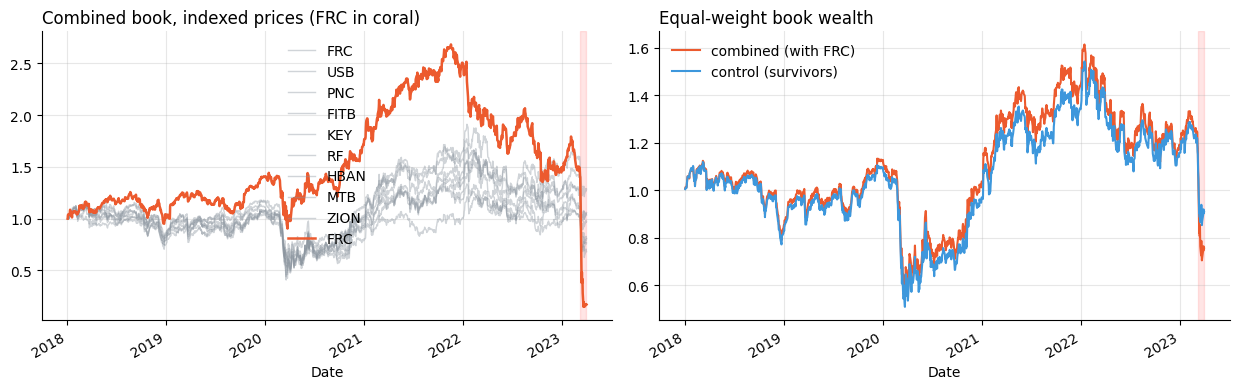

March 2023 log-return: combined -51.5% vs control -30.7%


In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4))
px = books['combined (FRC + 8 survivors)']['px']
(px / px.iloc[0]).plot(ax=a1, lw=1.0, alpha=.4, color=GREY, legend=False)
(px['FRC'] / px['FRC'].iloc[0]).plot(ax=a1, lw=1.8, color=CORAL, label='FRC')
a1.set_title('Combined book, indexed prices (FRC in coral)', loc='left'); a1.legend(frameon=False)
ew_c = books['combined (FRC + 8 survivors)']['rets'].mean(axis=1)
ew_s = books['control (8 survivors)']['rets'].mean(axis=1)
np.exp(ew_c.cumsum()).plot(ax=a2, color=CORAL, lw=1.5, label='combined (with FRC)')
np.exp(ew_s.cumsum()).plot(ax=a2, color=BLUE, lw=1.5, label='control (survivors)')
a2.set_title('Equal-weight book wealth', loc='left'); a2.legend(frameon=False)
for ax in (a1, a2): ax.axvspan(pd.Timestamp('2023-03-08'), pd.Timestamp('2023-03-31'), color='red', alpha=.10)
plt.tight_layout(); plt.show()
mar_c = ew_c.loc['2023-03'].sum(); mar_s = ew_s.loc['2023-03'].sum()
print(f'March 2023 log-return: combined {mar_c:+.1%} vs control {mar_s:+.1%}')

## 2 — The head-to-head: $\Delta_{HO}$ on the doomed book vs the control

Top: the gauge on both books. Middle: the **difference** (combined − control) — the marginal
higher-order fragility attributable to holding the failing bank. Bottom: the absorption ratio on
both books — the classical dial given the same chance. SVB week shaded.

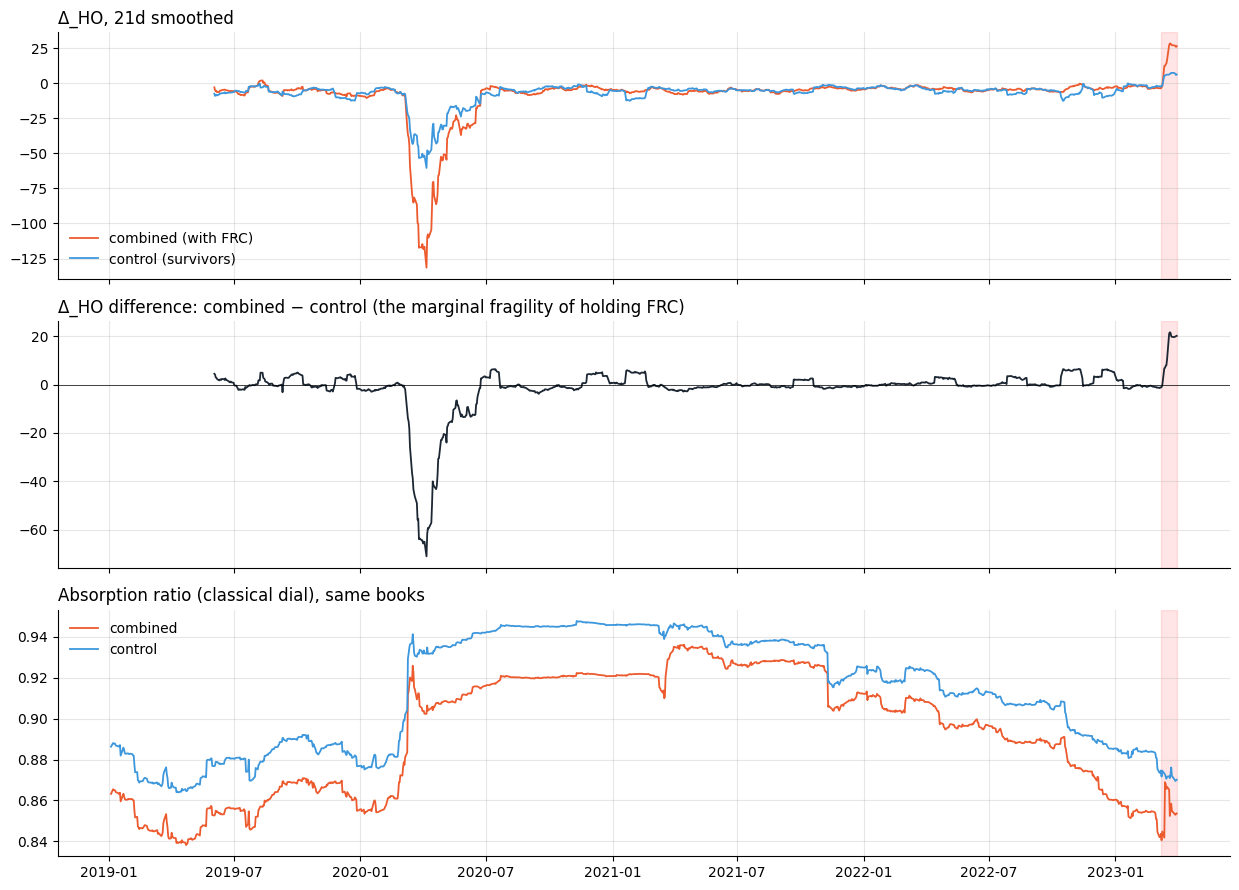

In [3]:
g_c = books['combined (FRC + 8 survivors)']['dhi']['delta_ho_sm'].dropna()
g_s = books['control (8 survivors)']['dhi']['delta_ho_sm'].dropna()
common = g_c.index.intersection(g_s.index)
diff = (g_c.loc[common] - g_s.loc[common])

WIN = 252
def absorption(rets):
    X = rets.to_numpy(); n_eig = max(1, round(rets.shape[1] / 5))
    vals = np.full(len(rets), np.nan)
    for t in range(WIN, len(rets)):
        ev = np.sort(np.linalg.eigvalsh(np.corrcoef(X[t - WIN:t].T)))[::-1]
        vals[t] = ev[:n_eig].sum() / ev.sum()
    return pd.Series(vals, index=rets.index).dropna()
ar_c = absorption(books['combined (FRC + 8 survivors)']['rets'])
ar_s = absorption(books['control (8 survivors)']['rets'])

fig, axes = plt.subplots(3, 1, figsize=(12.5, 9), sharex=True)
axes[0].plot(g_c.index, g_c.values, color=CORAL, lw=1.3, label='combined (with FRC)')
axes[0].plot(g_s.index, g_s.values, color=BLUE, lw=1.3, label='control (survivors)')
axes[0].set_title('Δ_HO, 21d smoothed', loc='left'); axes[0].legend(frameon=False)
axes[1].plot(diff.index, diff.values, color=DARK, lw=1.3)
axes[1].axhline(0, color='k', lw=.5)
axes[1].set_title('Δ_HO difference: combined − control (the marginal fragility of holding FRC)', loc='left')
axes[2].plot(ar_c.index, ar_c.values, color=CORAL, lw=1.3, label='combined')
axes[2].plot(ar_s.index, ar_s.values, color=BLUE, lw=1.3, label='control')
axes[2].set_title('Absorption ratio (classical dial), same books', loc='left'); axes[2].legend(frameon=False)
for ax in axes:
    ax.axvspan(pd.Timestamp('2023-03-08'), pd.Timestamp('2023-03-31'), color='red', alpha=.10)
plt.tight_layout(); plt.show()

## 3 — Zoom: the six months before the collapse

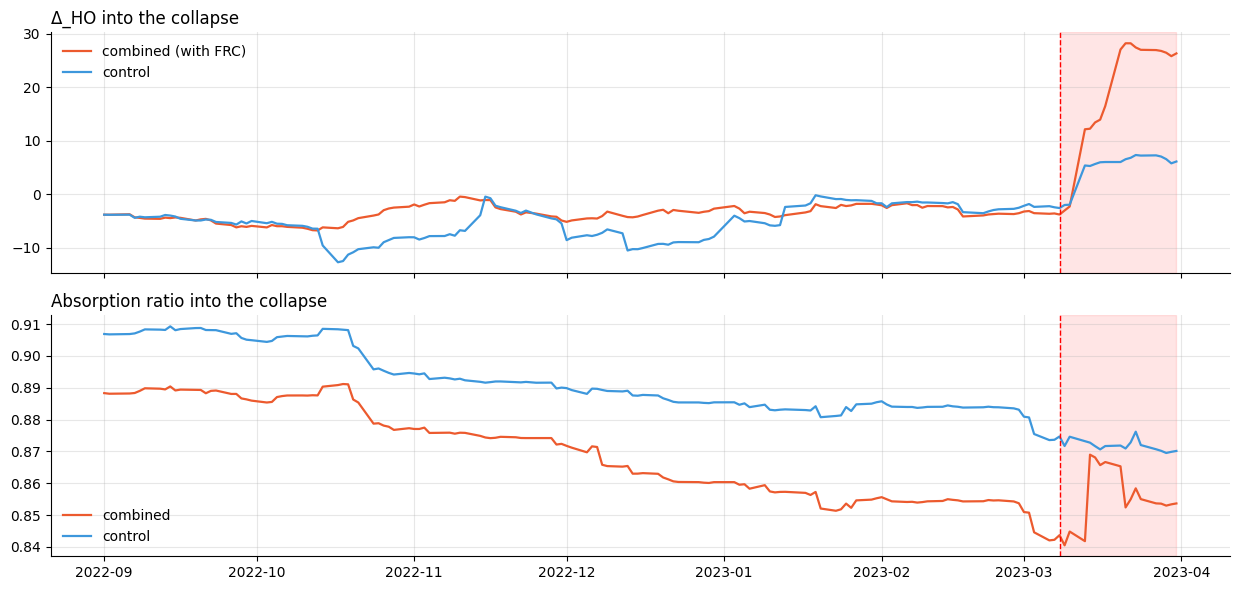

In [4]:
z0, z1 = '2022-09-01', '2023-03-31'
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12.5, 6), sharex=True)
a1.plot(g_c.loc[z0:z1].index, g_c.loc[z0:z1].values, color=CORAL, lw=1.6, label='combined (with FRC)')
a1.plot(g_s.loc[z0:z1].index, g_s.loc[z0:z1].values, color=BLUE, lw=1.6, label='control')
a1.set_title('Δ_HO into the collapse', loc='left'); a1.legend(frameon=False)
a2.plot(ar_c.loc[z0:z1].index, ar_c.loc[z0:z1].values, color=CORAL, lw=1.6, label='combined')
a2.plot(ar_s.loc[z0:z1].index, ar_s.loc[z0:z1].values, color=BLUE, lw=1.6, label='control')
a2.set_title('Absorption ratio into the collapse', loc='left'); a2.legend(frameon=False)
for ax in (a1, a2):
    ax.axvline(pd.Timestamp('2023-03-08'), color='red', lw=1, ls='--')
    ax.axvspan(pd.Timestamp('2023-03-08'), pd.Timestamp('2023-03-31'), color='red', alpha=.10)
plt.tight_layout(); plt.show()

## 4 — The scorecard: separation before the event

For each dial, the question a risk owner cares about: **in the run-up windows before 2023-03-08,
how differently did the dial read the doomed book vs the control?** We report the mean gap
(combined − control) in each window, expressed in units of the dial's own full-sample standard
deviation on the control book (so the two dials are comparable), plus each book's percentile rank
of its own history at the eve of the collapse.

In [5]:
eve = pd.Timestamp('2023-03-07')
windows = {'last 1m': 21, 'last 3m': 63, 'last 6m': 126, 'last 12m': 252}
rows = []
# NOTE: the combined book has 9 assets vs the control's 8, so each dial's LEVEL carries a
# structural book-size offset. We therefore score the ABNORMAL gap: the window's mean gap minus
# the gap's own full-pre-eve baseline, in units of the gap's own standard deviation.
for dial, (sc, ss) in (('Δ_HO (MPS)', (g_c, g_s)), ('Absorption ratio', (ar_c, ar_s))):
    common_d = sc.index.intersection(ss.index)
    gap = (sc.loc[common_d] - ss.loc[common_d]).loc[:eve]
    base_mu, base_sd = gap.mean(), gap.std()
    for wname, n in windows.items():
        w = gap.tail(n)
        rows.append({'dial': dial, 'window': wname,
                     'abnormal gap (gap sd)': (w.mean() - base_mu) / base_sd,
                     'share of days gap > baseline': (w > base_mu).mean()})
tbl = pd.DataFrame(rows).set_index(['dial', 'window'])
print(tbl.to_string(float_format=lambda v: f'{v:+.2f}'))

for name, s in (('Δ_HO combined', g_c), ('Δ_HO control', g_s),
                ('AR combined', ar_c), ('AR control', ar_s)):
    hist = s.loc[:eve]
    print(f'{name:16s} eve-of-collapse percentile of own history: {(hist <= hist.iloc[-1]).mean():.0%}')

                           abnormal gap (gap sd)  share of days gap > baseline
dial             window                                                       
Δ_HO (MPS)       last 1m                   +0.09                         +1.00
                 last 3m                   +0.30                         +0.98
                 last 6m                   +0.34                         +0.99
                 last 12m                  +0.31                         +1.00
Absorption ratio last 1m                   -1.68                         +0.00
                 last 3m                   -1.24                         +0.05
                 last 6m                   -0.47                         +0.52
                 last 12m                  +0.06                         +0.76
Δ_HO combined    eve-of-collapse percentile of own history: 79%
Δ_HO control     eve-of-collapse percentile of own history: 90%
AR combined      eve-of-collapse percentile of own history: 2%
AR control       ev

## 5 — Reading the result honestly

Three possible outcomes, all informative:

1. **The gauge separates the books before the event and the absorption ratio does not** — the
   marginal-fragility story: holding the failing bank changed the book's higher-order dependence
   signature in a way linear coupling did not register. This is the strongest PM value demo the
   module can produce.
2. **Both dials separate** — fragility was visible classically too; the gauge corroborates with a
   dependence-shape reading (still useful, weaker as a differentiator).
3. **Neither separates** — an honest boundary: one failing name among nine, in a sector-wide
   panic that hit survivors too (the control also fell ~25% in March), may simply not be visible
   at the book level before the run. Week-7 discipline says we report this as readily as a win.

Whatever the table above shows, the caveats stand: one event (n=1), one failure name (SVB and
Signature histories unrecoverable), descriptive attribution rather than a forecast claim, and the
gauge's known ~50% redundancy with the absorption ratio applies here too.